# PART 1

## A. Feature selection

In the following excercises `fetch20newsgroups` wil bee analyzed. Features representing the documents will be evaluated from the point of view of a classifiaction task using different feature evaluation criteria. 

Choose (uncomment) several (3-5) groups from the data set. These groups will be regarded as different classes.

In [1]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer

categories = [
    'alt.atheism',
    # 'comp.graphics',
    #'comp.os.ms-windows.misc',
    #'comp.sys.ibm.pc.hardware',
    #'comp.sys.mac.hardware',
    # 'comp.windows.x',
    #'misc.forsale',
    #'rec.autos',
    #'rec.motorcycles',
    #'rec.sport.baseball',
    #'rec.sport.hockey',
    #'sci.crypt',
    #'sci.electronics',
    # 'sci.med',
    'sci.space',
    #'soc.religion.christian',
    'talk.politics.guns',
    #'talk.politics.mideast',
    #'talk.politics.misc',
    #'talk.religion.misc'
]
dataset = fetch_20newsgroups(subset='all', categories = categories, shuffle=True, random_state=42)

Converting documents to feature vectors.

In [2]:
vectorizer = TfidfVectorizer(max_df=0.5, min_df=2, max_features = None, stop_words='english')
docs_vectors = vectorizer.fit_transform(dataset.data)
print("Number of documents: %d\nNumber of features: %d" %docs_vectors.shape)

Number of documents: 2696
Number of features: 20257


Splitting data into trainig and test set.

In [3]:
from sklearn.model_selection import train_test_split
data_train, data_test, target_train, target_test = train_test_split(docs_vectors, dataset.target, test_size=0.33, random_state=0)

Classifier training.

In [4]:
from sklearn import tree
tree = tree.DecisionTreeClassifier()
tree.fit(data_train, target_train)
print("Classification error for the test set is: ", 1.0 - tree.score(data_test,target_test))

Classification error for the test set is:  0.11573033707865166


To perform feature selection class `SelectKBest` may be used. It lets evaluate features on the basis of a mearue given as a function argument. 

http://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html#sklearn.feature_selection.SelectKBest

The `fit` method calculates the measure value for each feature. These values may be read from attribute `scores_`.

The `transform` method modifies data set by leaving only given number of features, which achieved the highest scores.

The `fit_transform` method performs both scoring features and modifying data set. The same effect may be obtained after applying `fit` followed by `transform`.

In [5]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif, chi2

select_mutual = SelectKBest(chi2, k = 100)
select_mutual.fit(data_train, target_train)

select_mutual.scores_

array([1.23024718, 1.24762441, 0.28927974, ..., 0.19933998, 0.97979793,
       0.15320988], shape=(20257,))

**Excercise 1**

Modify the data set by leaving only N features, which achieve the highest values of chi2 score.  Train and test the decision tree after the modifiation. Does feature reduction change the value of classification error? Find the optimal value of N, i.e. the value minimizing classification error. Remember, that test data shoud never take part in adjusting the number of features. It means you need to split data into training and testing subsets first. Adjust N on the basis of training data in a cross-validation procedure. Then train the final tree for the identified optimal N on the basis of training subset and test it on the basis of test subset. 

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.tree import DecisionTreeClassifier

pipe = Pipeline([
    ('feature_selection', SelectKBest(score_func=chi2)),
    ('classification', DecisionTreeClassifier(random_state=0))
])

param_grid = {
    'feature_selection__k': [50, 100, 200, 500, 1000, 2000, 3000, 'all']
}

grid_search = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(data_train, target_train)

optimal_n = grid_search.best_params_['feature_selection__k']
val_error = 1.0 - grid_search.best_score_
test_error = 1.0 - grid_search.score(data_test, target_test)

print(f"Optimal N (number of features): {optimal_n}")
print(f"Cross-Validation Error (Training subset): {val_error:.4f}")
print(f"Final Test Set Error: {test_error:.4f}")

if optimal_n != 'all':
    print(f"Feature reduction {'reduced' if val_error < (1.0 - tree.score(data_train, target_train)) else 'did not significantly reduce'} error compared to base model.")

Optimal N (number of features): 200
Cross-Validation Error (Training subset): 0.0941
Final Test Set Error: 0.1101
Feature reduction did not significantly reduce error compared to base model.


**Excercise 2**

Display 30 words regarding features achieving the highest scores of chi2. Can you see the relation between the words and the classes?

In [7]:
import numpy as np

feature_names = vectorizer.get_feature_names_out()

selector = SelectKBest(chi2, k='all').fit(data_train, target_train)

scores = selector.scores_
scores[np.isnan(scores)] = 0.0

top_indices = np.argsort(scores)[-30:][::-1]

print(f"{'Rank':<5} {'Feature':<20} {'Chi2 Score'}")
print("-" * 40)
for i, idx in enumerate(top_indices):
    print(f"{i+1:<5} {feature_names[idx]:<20} {scores[idx]:.2f}")

Rank  Feature              Chi2 Score
----------------------------------------
1     space                53.17
2     gun                  45.41
3     god                  42.62
4     keith                37.02
5     sgi                  33.86
6     stratus              31.65
7     livesey              30.74
8     henry                30.33
9     atheists             29.31
10    fbi                  28.12
11    nasa                 27.01
12    guns                 25.58
13    morality             24.04
14    atheism              23.66
15    atf                  23.14
16    toronto              22.45
17    islam                22.33
18    solntze              22.15
19    wpd                  22.15
20    batf                 22.09
21    alaska               21.70
22    shuttle              21.26
23    moral                20.85
24    moon                 20.77
25    cdt                  20.30
26    jon                  20.17
27    waco                 20.09
28    digex                19.

### Answer to the question:

Yes, the relation is often obvious like space relates to sci.space, gun to talk.politics.guns, etc.
They indicate their classes the best so they achieve the highest chi square scores.

## B. Feature extraction

Principal component analysis (PCA) is a method commonly used to extract uncorrelated features. It is omplemented in `PCA` class. The `n_components` parameter of the method defines the number of extracted new features.

http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

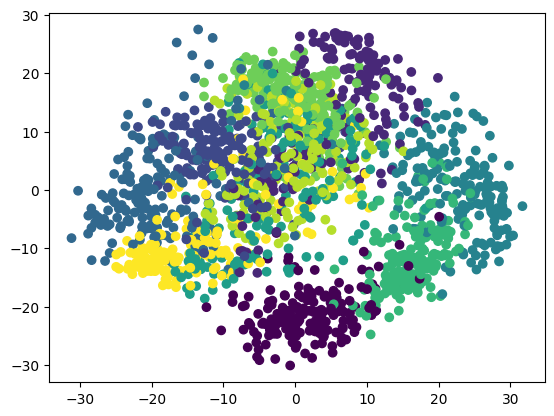

In [8]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
digits = load_digits(n_class=10)
X = digits.data
y = digits.target
n_samples, n_features = X.shape
pca = PCA(n_components = 2)
X_new = pca.fit_transform(X)
plt.scatter(X_new[:,0], X_new[:,1],c=y)
plt.show()

Linear discriminant analysis (LDA) is another feature extraction method. In contrast to PCA, it takes into account information about classes.

http://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html

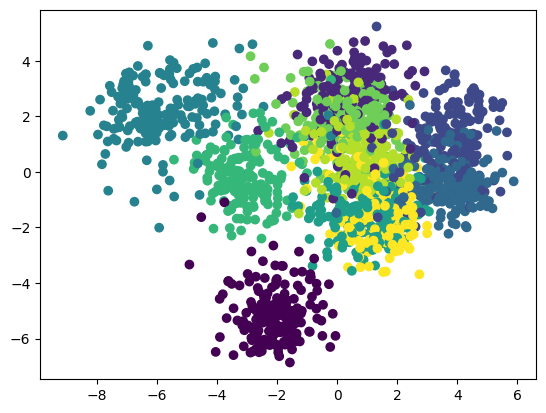

In [9]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)
plt.scatter(X_lda[:,0], X_lda[:,1], c=y)
plt.show()

**Excercise 3**

For `digits` data set, perform PCA and plot a graph showing the variance values for successive principal components. The graph should be drawn for all components. The variance values can be read from the `pca.explained_variance_ratio_` attribute. 

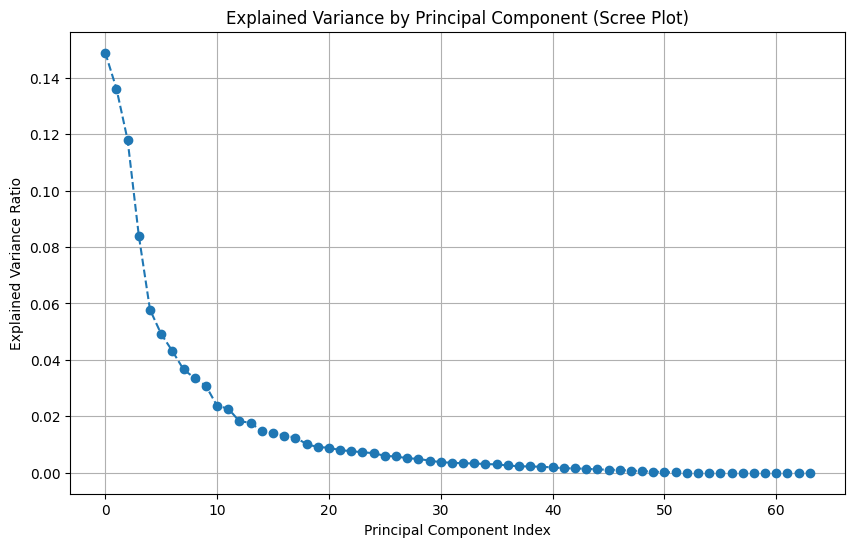

In [10]:
digits = load_digits()
X = digits.data

pca_all = PCA(n_components=None)
pca_all.fit(X)

plt.figure(figsize=(10, 6))
plt.plot(pca_all.explained_variance_ratio_, marker='o', linestyle='--')
plt.title('Explained Variance by Principal Component (Scree Plot)')
plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.grid(True)
plt.show()

**Excercise 4**

Write a function that returns the number of features that need to be included in order to retain a given amount of variance (sum of variances associated with each component) after performing PCA. The amount of variance should be given as a parameter of the function. This parameter may take values from the range (0; 1]. If the input parameter is 1, which means 100% variance, the function should return the maximum possible number of features. 

In [11]:
def get_n_features_for_variance(X, variance_threshold):
    if variance_threshold <= 0 or variance_threshold > 1:
        raise ValueError("Variance threshold must be in the range (0, 1].")
    pca = PCA(n_components=None)
    pca.fit(X)
    if variance_threshold == 1.0:
        return pca.n_components_
    cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
    n_components = np.argmax(cumulative_variance >= variance_threshold) + 1
    return n_components

In [12]:
digits = load_digits()
X = digits.data

thresholds = [0.85, 0.90, 0.95, 0.99, 1.0]

print(f"{'Variance':<10} | {'Features Needed'}")
print("-" * 25)

for t in thresholds:
    n = get_n_features_for_variance(X, t)
    print(f"{t:<10} | {n}")

Variance   | Features Needed
-------------------------
0.85       | 17
0.9        | 21
0.95       | 29
0.99       | 41
1.0        | 64


### Faces

The `fetch_olivetti_faces` data set contains 400 images of size 64x64 presenting 40 people. 

In [13]:
from sklearn.datasets import fetch_olivetti_faces
dataset = fetch_olivetti_faces(shuffle=True)
faces = dataset.data
n_samples, n_features = faces.shape

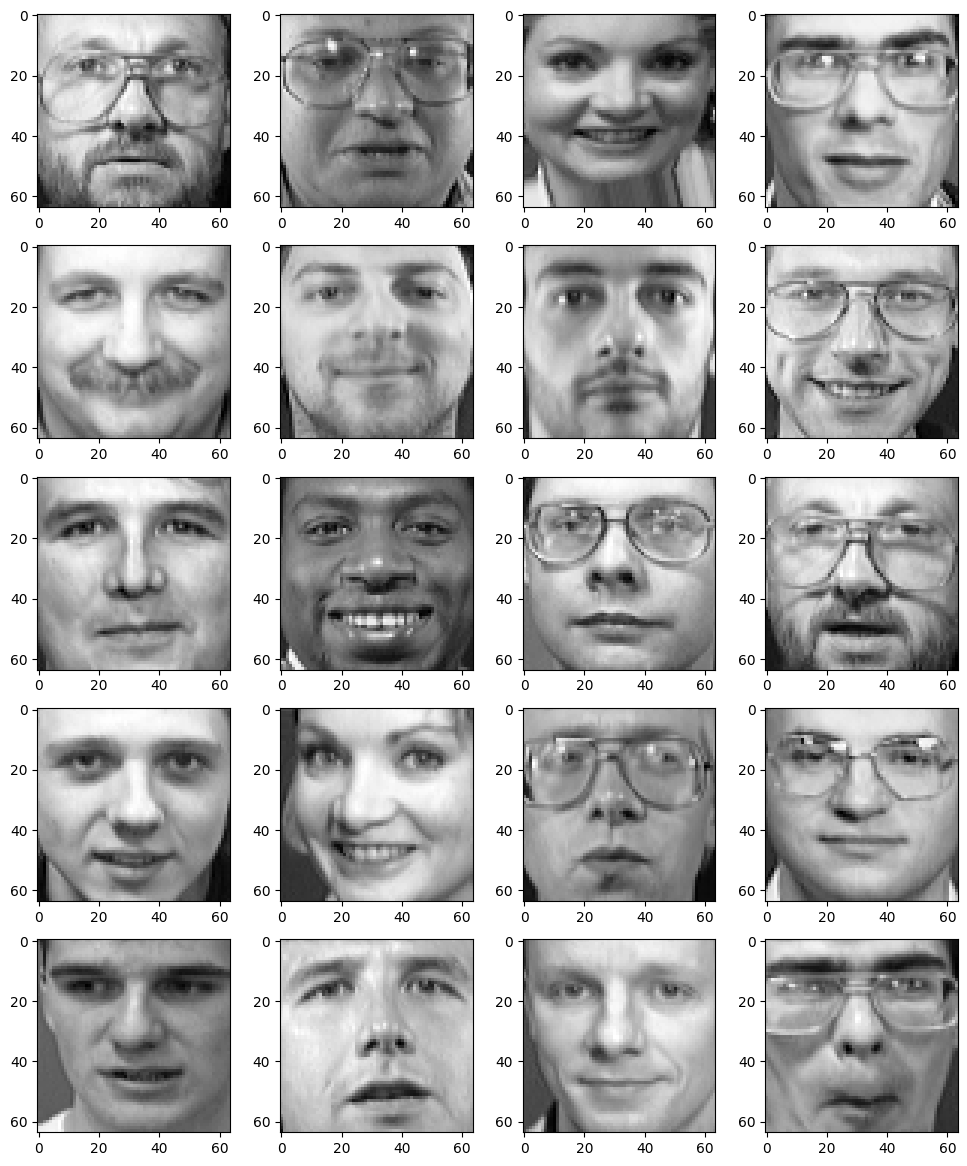

In [14]:
image_shape = (64, 64)
plt.figure(figsize = (3 * 4, 3* 100))
for i, image in enumerate(faces[:20,:]):
    plt.subplot(100, 4, i + 1)
    plt.imshow(image.reshape(image_shape), cmap=plt.cm.gray)
plt.show()

Below PCA is performed for the given data set. The obtained components (eigenvectors of the covariance matrix of the data) are then displayed as images.

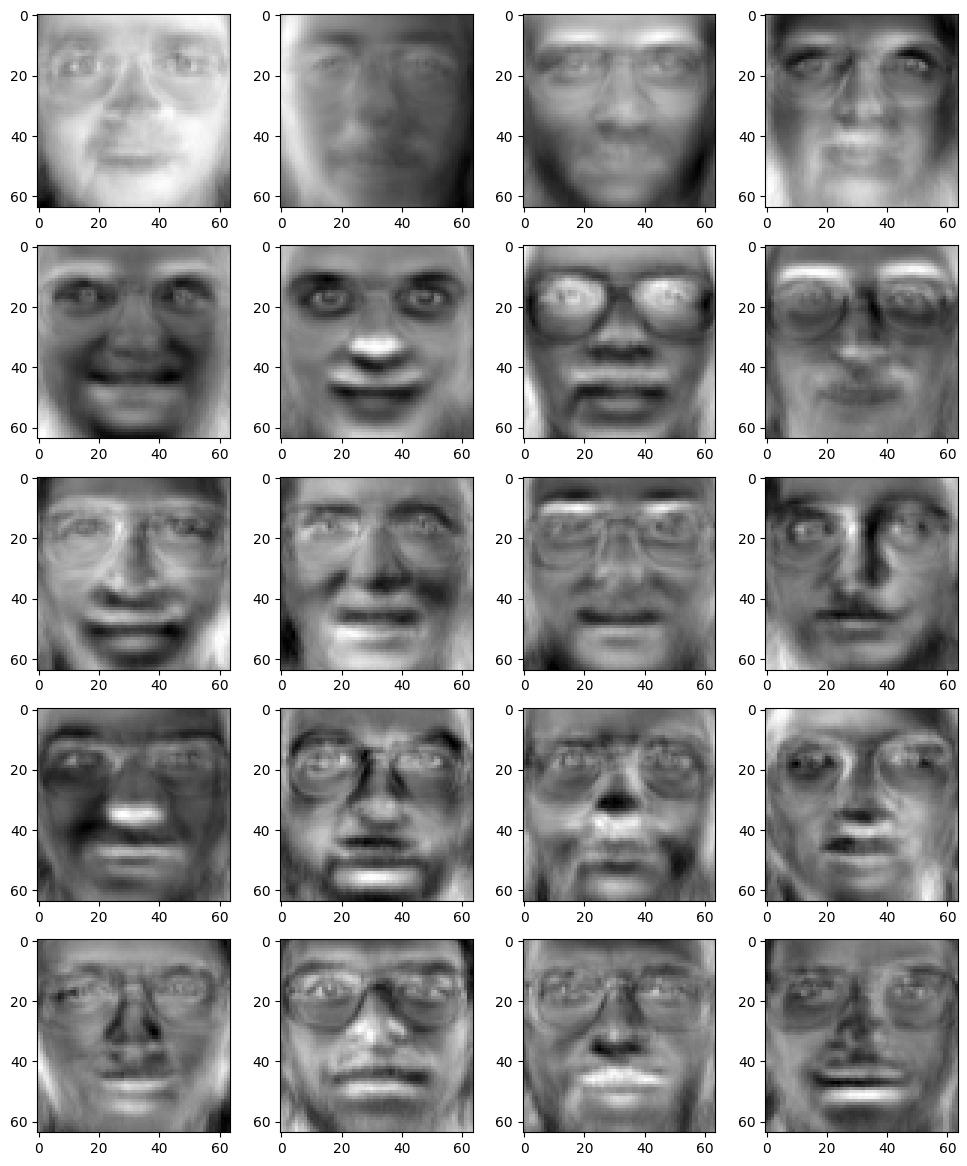

In [15]:
faces_centered = faces - faces.mean(axis=0)
pca = PCA(n_components=100)
pca.fit(faces_centered)
image_shape = (64, 64)
plt.figure(figsize = (3 * 4, 3* 100))
for i, image in enumerate(pca.components_[:20,:]):
    plt.subplot(100, 4, i + 1)
    plt.imshow(image.reshape(image_shape), cmap=plt.cm.gray)
plt.show()

**Excercise 5**

Reduce the number of features describing face images using PCA. Use the function implemented in Excercise 4 to decide on the final number of new features. Perform training and testing of a selected classifier recognizing people in photos.

Note 1: the number of features after transformation will be equal to the value of `n_components` or to the number of images in the set if there are less images than` n_components`.

Note 2: PCA should be performed on the basis of training data, while the test data should be transformed using the transformation matrix obtained by running PCA on the training data. Explain why it is not appropriate to use PCA on the complete data set (training + testing).


In [16]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

dataset = fetch_olivetti_faces(shuffle=True, random_state=42)
X = dataset.data
y = dataset.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

target_variance = 0.95
n_features = get_n_features_for_variance(X_train, target_variance)

print(f"Original feature count: {X_train.shape[1]}")
print(f"features needed for {target_variance*100}% variance: {n_features}")

pca = PCA(n_components=n_features, whiten=True, random_state=42)
pca.fit(X_train)

X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

clf = SVC(kernel='rbf', class_weight='balanced', random_state=42)
clf.fit(X_train_pca, y_train)

y_pred = clf.predict(X_test_pca)
accuracy = accuracy_score(y_test, y_pred)

print(f"Classifier Accuracy on Test Set: {accuracy:.4f}")

Original feature count: 4096
features needed for 95.0% variance: 109
Classifier Accuracy on Test Set: 0.9800


### Answer to question

Using PCA on the complete dataset (Train + Test) is the so-called 'Data Leakage'. 
PCA calculates eigenvectors based on the variance structure of the data. 
If you include the test set in this calculation, the model indirectly 'sees' 
the statistical properties of the test data during training. 

This leads to:
1. Over-optimistic performance estimates (the model looks better than it is).
2. Poor generalization to completely new, unseen real-world data.

Correct approach: Fit PCA on Training data only, then apply that same 
transformation to the Test data

## C. Parameter tuning

The `GridSearchCV` class enables training of the model and testing it for various parameters and the selection of a set of optimum parameters from the point of view of a given criterion (e.g. in the case of classifiers, this criterion is the minimum classification error). Testing the model for different parameter values is done in a cross-validation process. 

http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

In the example below, a decision tree for different attribute selection criteria and different values for the minimum number of examples in leaves will be trained for `digits` data.

In [17]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix #, accuracy_score
data_train, data_test, target_train, target_test = train_test_split(digits.data, digits.target, test_size=0.3, random_state=0)
tree = DecisionTreeClassifier()
parameters ={'criterion': ['gini', 'entropy'], 'min_samples_leaf': [5,4,3]}
search = GridSearchCV(tree, parameters, cv=5)
search.fit(data_train, target_train)

,estimator,DecisionTreeClassifier()
,param_grid,"{'criterion': ['gini', 'entropy'], 'min_samples_leaf': [5, 4, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'entropy'


The parameter values with the best score are saved in the `best_params_` attribute. 

In [18]:
search.best_params_

{'criterion': 'entropy', 'min_samples_leaf': 3}

Detailed results for each parameter set can be read from the attribute `cv_results_`.

In [19]:
search.cv_results_

{'mean_fit_time': array([0.00869446, 0.00867295, 0.00900936, 0.00945101, 0.00975494,
        0.01046767]),
 'std_fit_time': array([0.00048813, 0.00032462, 0.00040551, 0.00027858, 0.00026519,
        0.00052049]),
 'mean_score_time': array([0.00045547, 0.00034618, 0.00037003, 0.00037117, 0.00035906,
        0.00056944]),
 'std_score_time': array([1.35597313e-04, 6.76873663e-06, 5.21723919e-05, 4.00938679e-05,
        8.92208069e-06, 1.77509291e-04]),
 'param_criterion': masked_array(data=['gini', 'gini', 'gini', 'entropy', 'entropy',
                    'entropy'],
              mask=[False, False, False, False, False, False],
        fill_value=np.str_('?'),
             dtype=object),
 'param_min_samples_leaf': masked_array(data=[5, 4, 3, 5, 4, 3],
              mask=[False, False, False, False, False, False],
        fill_value=999999),
 'params': [{'criterion': 'gini', 'min_samples_leaf': 5},
  {'criterion': 'gini', 'min_samples_leaf': 4},
  {'criterion': 'gini', 'min_samples_leaf':

Testing the model for the best parameter settings.

In [20]:
search.score(data_test, target_test)

0.8407407407407408

## D. Pipeline processing

If our process consists of several stages, the `Pipeline` class can be used.

http://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

The following example defines a process consisting of a feature extractor (PCA) and a classifier (decision tree).

In [21]:
from sklearn.pipeline import Pipeline
pipe = Pipeline([('extract', PCA()), ('classify', DecisionTreeClassifier())])

Pipelining is usually combined with the search for the optimum set of parameters. As a parameter of the function `GridSearchCV`, you should pass an object representing our multi-stage process. In the example below, optimum value of the number of components of PCA is seached in the defined pipeline. The names of the parameters are created by combining the name of the stage (`extract`) with the name of the appropriate parameter (` n_components`) using underscores.

In [22]:
parameters = {'extract__n_components': [10,20,30]}
search = GridSearchCV(pipe, parameters, cv=5)
search.fit(data_train, target_train)

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'extract__n_components': [10, 20, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_components,10


In [23]:
search.best_params_

{'extract__n_components': 10}

In [24]:
search.score(data_test, target_test)

0.8685185185185185

# PART 2

1. Load the assigned dataset and split it into train (60%), validation (20%), and test (20%).

2. Use three dimensionality-reduction or feature-selection techniques:

>a. SelectKBest(chi2) or SelectKBest(mutual_info_classif)

>b. PCA

>c. LDA (for labeled data only)

3. Train at least two classifiers (e.g. Logistic Regression, Random Forest, or SVM). Create proper pipelines combining step 2 and 3.

4. Evaluate each technique using validation performance, test performance, and computational cost.

5. Produce:

>a. Scree plot (PCA explained variance)

>b. Classification accuracy vs. number of features/components

>c. 2D visualization of transformed data (PCA/LDA)

6. Discuss:

>a. Why some features/components are more informative than others

>b. How selection/extraction impacts effectiveness of your classifiers

>c. Whether results generalize across classifiers

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# First split: 60% Train, 40% Temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
# Second split: Split the 40% Temp into two halves (20% Val, 20% Test)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Train shape: {X_train.shape}, Val shape: {X_val.shape}, Test shape: {X_test.shape}")



Train shape: (341, 30), Val shape: (114, 30), Test shape: (114, 30)


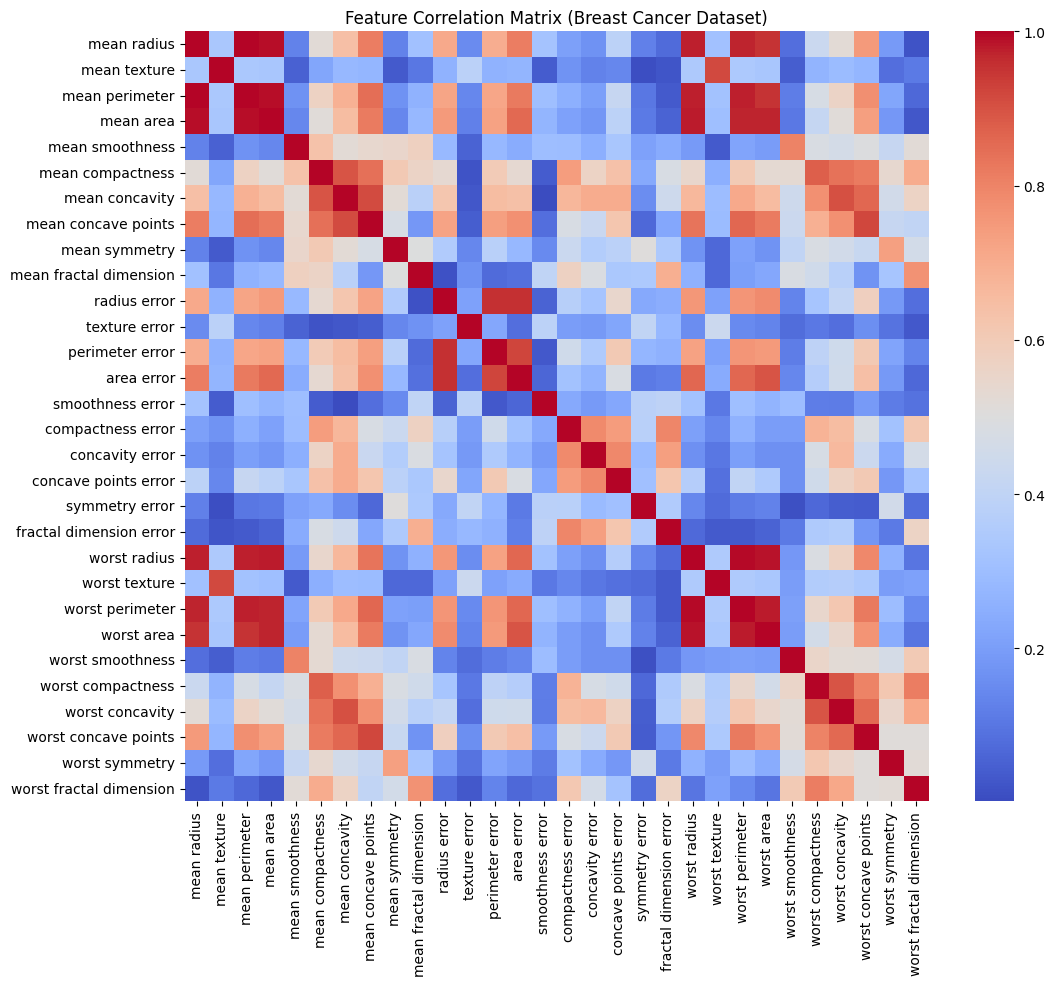

Number of features with correlation > 0.95: 7
Examples: ['mean perimeter', 'mean area', 'perimeter error']


In [26]:
# REDUNDANCY (my task)
corr_matrix = X_train.corr().abs()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title("Feature Correlation Matrix (Breast Cancer Dataset)")
plt.show()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
print(f"Number of features with correlation > 0.95: {len(to_drop)}")
print(f"Examples: {to_drop[:3]}")

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
import time

classifiers = {
    'LogReg': LogisticRegression(max_iter=10000, random_state=42),
    'RandForest': RandomForestClassifier(n_estimators=50, random_state=42)
}

k_values = [2, 5, 10, 15, 20, 25, 30] 

results = []

# Loop through techniques
for name, clf in classifiers.items():
    for k in k_values:
        # SelectKBest
        pipe_kbest = Pipeline([
            ('scaler', StandardScaler()),
            ('selector', SelectKBest(mutual_info_classif, k=k)),
            ('classifier', clf)
        ])
        
        start = time.time()
        pipe_kbest.fit(X_train, y_train)
        train_time = time.time() - start
        val_acc = accuracy_score(y_val, pipe_kbest.predict(X_val))
        results.append({'Method': 'SelectKBest', 'Classifier': name, 'K': k, 'Val_Acc': val_acc, 'Time': train_time})

        # PCA
        pipe_pca = Pipeline([
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=k)),
            ('classifier', clf)
        ])
        
        start = time.time()
        pipe_pca.fit(X_train, y_train)
        train_time = time.time() - start
        val_acc = accuracy_score(y_val, pipe_pca.predict(X_val))
        results.append({'Method': 'PCA', 'Classifier': name, 'K': k, 'Val_Acc': val_acc, 'Time': train_time})

    # LDA
    pipe_lda = Pipeline([
        ('scaler', StandardScaler()),
        ('lda', LDA(n_components=1)),
        ('classifier', clf)
    ])
    start = time.time()
    pipe_lda.fit(X_train, y_train)
    train_time = time.time() - start
    val_acc = accuracy_score(y_val, pipe_lda.predict(X_val))
    results.append({'Method': 'LDA', 'Classifier': name, 'K': 1, 'Val_Acc': val_acc, 'Time': train_time})

df_results = pd.DataFrame(results)

In [28]:
df_results

,Method,Classifier,K,Val_Acc,Time
0,SelectKBest,LogReg,2,0.938596,0.042673
1,PCA,LogReg,2,0.956140,0.003504
2,SelectKBest,LogReg,5,0.964912,0.045676
3,PCA,LogReg,5,0.982456,0.003453
4,SelectKBest,LogReg,10,0.964912,0.053453
5,PCA,LogReg,10,0.982456,0.003906
6,SelectKBest,LogReg,15,0.964912,0.045835
7,PCA,LogReg,15,0.982456,0.003695
8,SelectKBest,LogReg,20,0.991228,0.046509
9,PCA,LogReg,20,0.991228,0.003832


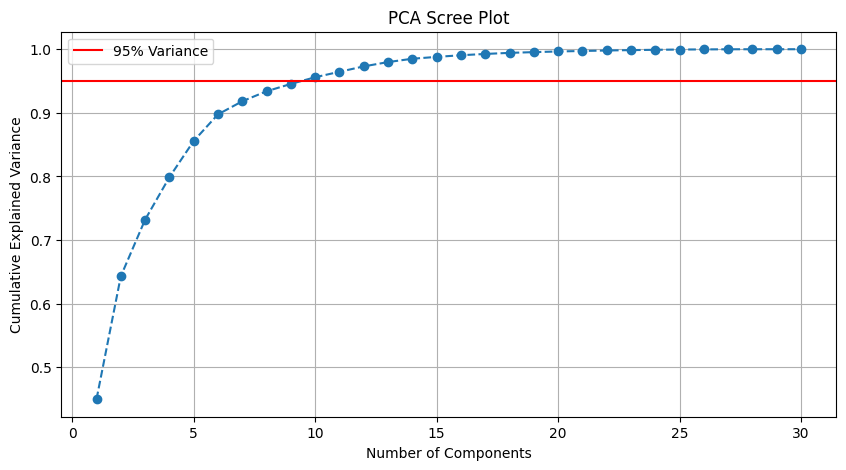

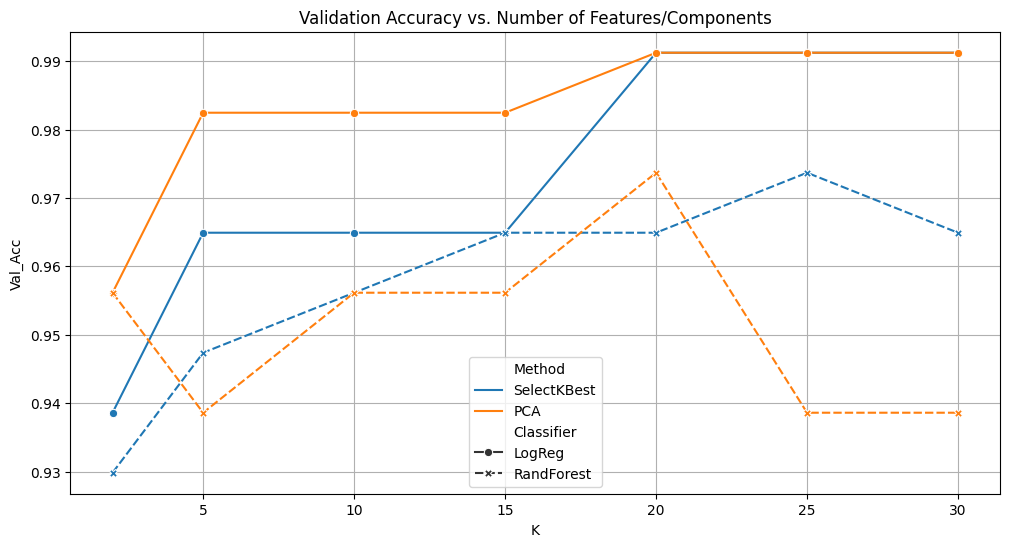

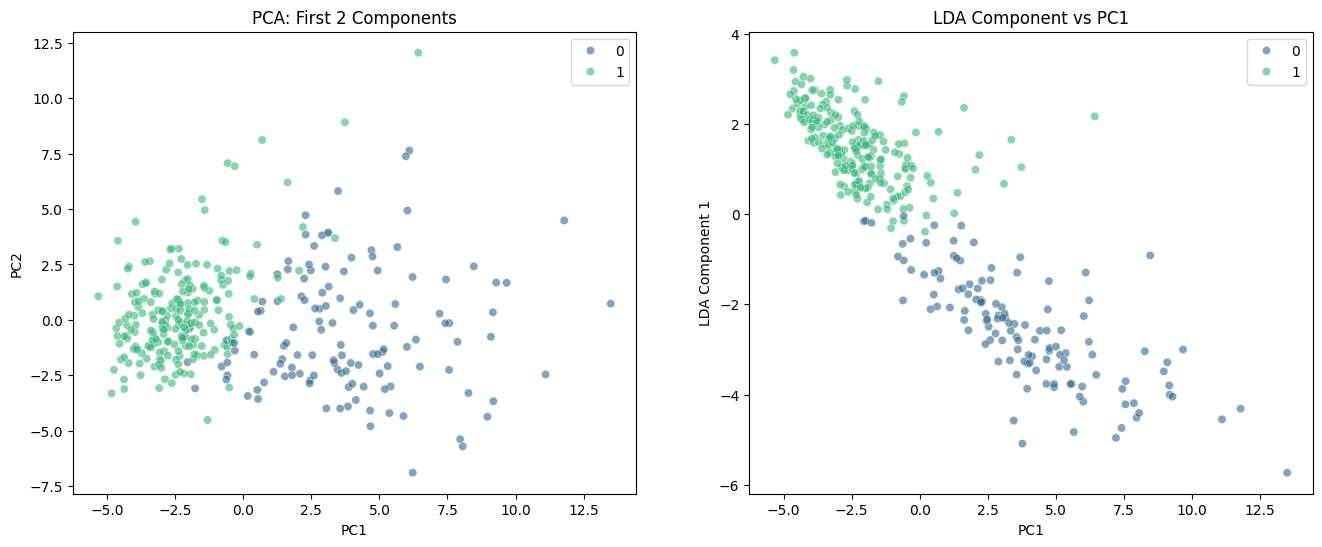

In [29]:
# Scree Plot
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
pca_full = PCA(n_components=30)
pca_full.fit(X_train_scaled)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 31), np.cumsum(pca_full.explained_variance_ratio_), marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Scree Plot')
plt.legend()
plt.grid()
plt.show()

# Classification Accuracy vs K
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_results[df_results['Method'] != 'LDA'], x='K', y='Val_Acc', hue='Method', style='Classifier', markers=True)
plt.title('Validation Accuracy vs. Number of Features/Components')
plt.grid()
plt.show()

# 2D Visualization (PCA vs LDA)
# PCA 2D
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_train_scaled)

# LDA 1D
lda = LDA(n_components=1)
X_lda_1d = lda.fit_transform(X_train_scaled, y_train)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PCA Plot
sns.scatterplot(x=X_pca_2d[:,0], y=X_pca_2d[:,1], hue=y_train, palette='viridis', ax=axes[0], alpha=0.6)
axes[0].set_title('PCA: First 2 Components')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# LDA vs PC1 Plot (Since LDA is 1D here)
sns.scatterplot(x=X_pca_2d[:,0], y=X_lda_1d.ravel(), hue=y_train, palette='viridis', ax=axes[1], alpha=0.6)
axes[1].set_title('LDA Component vs PC1')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('LDA Component 1')

plt.show()

### Discussion of Results

#### Impact of redundancy (PCA vs. SelectKBest)

- The Breast Cancer dataset contains high feature redundancy (e.g., radius, perimeter, and area are correlated).
- **PCA** (Extraction): Efficiently handled redundancy. By creating orthogonal components, PCA + Logistic Regression achieved 98.2% accuracy with only 5 components. The Scree plot confirms that 6 components explain about 90% of the variance.
- **SelectKBest** (Selection): Struggled with redundancy. It likely selected highly correlated top features, adding "volume" but not "information." Consequently, it required 20 features to match the accuracy PCA achieved with just 5.

#### Classifier Generalization
- The effectiveness of dimensionality reduction did not generalize across classifiers.
- Logistic Regression: worked very well with PCA and LDA. As a linear model, it achieves very good results by removing multicollinearity (PCA) and maximizing class separability (LDA).
- Random Forest: was worse with PCA. While stable with SelectKBest (raw features), its performance went down at higher PCA components (K=25, acc went down to about 93.8%). Tree-based models prefer raw, interpretable splits and struggle when features are rotated linear combinations of the original space.

#### The Efficiency Winner: LDA
LDA reduced the dataset to a single component (due to binary classes) while maintaining 97.4% accuracy with Logistic Regression. This indicates the data is highly linearly separable and makes LDA the most computationally efficient choice for deployment.